# One-dimensional Optimization

**Seong Cho** · ACME Volume 2, Lab 11

**Lab objective:** implement the golden section search method, Newton's method, and the secant method for optimizing functions of a single variable, then apply them to the backtracking problem.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

> **Note.** This notebook requires [Autograd](https://github.com/HIPS/autograd) (install it with `pip install autograd`), which Problem 4 uses for SciPy's comparison step size. It was run with autograd 1.9.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from autograd import numpy as anp
from autograd import grad

Most mathematical optimization problems involve estimating the minimizer(s) of a scalar-valued function. Many algorithms for optimizing functions with a high-dimensional domain depend on routines for optimizing functions of a single variable, and there are many techniques for optimization in one dimension, each with varying degrees of precision and speed.

## Golden Section Search

A function $f : [a, b] \to \mathbb{R}$ satisfies the *unimodal property* if it has exactly one local minimum and is monotonic on either side of the minimizer: $f$ decreases from $a$ to its minimizer $x^*$, then increases up to $b$. The *golden section search* optimizes a unimodal function by iteratively defining smaller and smaller intervals containing $x^*$. It is especially useful if the function's derivative does not exist, is unknown, or is very costly to compute.

To shrink the interval $[a, b]$ around $x^*$, test the strategically chosen points

$$\tilde{a} = b - \frac{b-a}{\varphi}, \qquad \tilde{b} = a + \frac{b-a}{\varphi},$$

where $\varphi = \frac{1+\sqrt{5}}{2}$ is the golden ratio. At each step $[a, b]$ is refined to either $[a, \tilde{b}]$ or $[\tilde{a}, b]$, the *golden sections*. If $f(\tilde{a}) < f(\tilde{b})$, then since $f$ is unimodal it must be increasing in a neighborhood of $\tilde{b}$, and on all of $[\tilde{b}, b]$, so $x^* \in [a, \tilde{b}]$ and we set $b = \tilde{b}$. Similarly, if $f(\tilde{a}) > f(\tilde{b})$, then $x^* \in [\tilde{a}, b]$ and we set $a = \tilde{a}$. If $f(\tilde{a}) = f(\tilde{b})$, unimodality guarantees nothing about where the minimizer lies; assuming either section lets the iteration continue, but convergence to the local minimum is no longer guaranteed. (The spec's Figure 11.1 illustrates a first iteration with $f(\tilde{a}) < f(\tilde{b})$, so $x^* \in [a, \tilde{b}]$.)

At each iteration the length of the search interval is divided by $\varphi$, so the method converges linearly, which is somewhat slow. However, the idea is simple and each step is computationally inexpensive.

```text
Algorithm 11.1  The Golden Section Search
 1: procedure golden_section(f, a, b, tol, maxiter)
 2:     x0 ← (a + b)/2              ▷ Set the initial minimizer approximation as the interval midpoint.
 3:     φ = (1 + √5)/2
 4:     for i = 1, 2, ..., maxiter do  ▷ Iterate only maxiter times at most.
 5:         c ← (b − a)/φ
 6:         ã ← b − c
 7:         b̃ ← a + c
 8:         if f(ã) ≤ f(b̃) then     ▷ Get new boundaries for the search interval.
 9:             b ← b̃
10:         else
11:             a ← ã
12:         x1 ← (a + b)/2          ▷ Set the minimizer approximation as the interval midpoint.
13:         if |x0 − x1| < tol then
14:             break               ▷ Stop iterating if the approximation stops changing enough.
15:         x0 ← x1
16:     return x1
```

## Problem 1: Golden section search

> **Problem 1.** Write a function that accepts a function $f : \mathbb{R} \to \mathbb{R}$, interval limits $a$ and $b$, a stopping tolerance `tol`, and a maximum number of iterations `maxiter`. Use Algorithm 11.1 to implement the golden section search. Return the approximate minimizer $x^*$, whether or not the algorithm converged (true or false), and the number of iterations computed.
>
> Test your function by minimizing $f(x) = e^x - 4x$ on the interval $[0, 3]$, then plotting the function and the computed minimizer together. Also compare your results to SciPy's golden section search, `scipy.optimize.golden()`.

The spec's SciPy comparison ($\ln(4)$ is the minimizer):

In [2]:
f = lambda x : np.exp(x) - 4*x
opt.golden(f, brack=(0,3), tol=.001)

np.float64(1.3862578679031485)

In [3]:
def golden_section(f, a, b, tol=1e-5, maxiters=15):
    """Use the golden section search to minimize the unimodal function f.

    Parameters:
        f (function): A unimodal, scalar-valued function on [a,b].
        a (float): Left bound of the domain.
        b (float): Right bound of the domain.
        tol (float): The stopping tolerance.
        maxiters (int): The maximum number of iterations to compute.

    Returns:
        (float): The approximate minimizer of f.
        (bool): Whether or not the algorithm converged.
        (int): The number of iterations computed.
    """
    # Algorithm 11.1
    x0 = (a + b) / 2
    r = (1 + np.sqrt(5))/2
    # Keep track of convergence and the number of iterations
    converged = False
    iterations = 0
    for i in range(maxiters):
        iterations += 1
        c = (b - a) / r
        a_1 = b - c
        b_1 = a + c
        if f(a_1) <= f(b_1):
            b = b_1
        else:
            a = a_1
        x1 = (a + b) / 2
        if abs(x0 - x1) < tol:
            converged = True
            break
        x0 = x1

    return x1, converged, iterations

tol = 1e-3: x* = 1.3859982671, converged = True, iterations = 15
tol = 1e-8: x* = 1.3862943541, converged = True, iterations = 39
opt.golden(tol=1e-8) = 1.3862943682
minimize_scalar      = 1.3862944223
ln(4)                = 1.3862943611


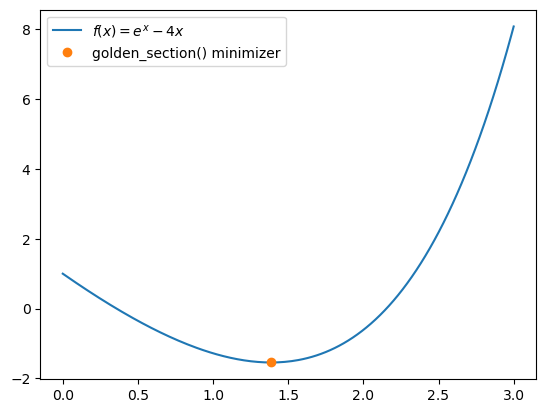

In [4]:
f = lambda x: np.exp(x) - 4*x
xmin, conv, niters = golden_section(f, 0, 3, tol=1e-3, maxiters=100)
print(f"tol = 1e-3: x* = {xmin:.10f}, converged = {conv}, iterations = {niters}")
xmin5, conv5, niters5 = golden_section(f, 0, 3, tol=1e-8, maxiters=100)
print(f"tol = 1e-8: x* = {xmin5:.10f}, converged = {conv5}, iterations = {niters5}")
print(f"opt.golden(tol=1e-8) = {opt.golden(f, brack=(0, 3), tol=1e-8):.10f}")
print(f"minimize_scalar      = {opt.minimize_scalar(f, bounds=(0, 3), method='bounded').x:.10f}")
print(f"ln(4)                = {np.log(4):.10f}")
assert conv and abs(xmin - np.log(4)) < 1e-3
assert conv5 and abs(xmin5 - np.log(4)) < 1e-7

dom = np.linspace(0, 3, 200)
plt.plot(dom, f(dom), label="$f(x) = e^x - 4x$")
plt.plot(xmin5, f(xmin5), "o", label="golden_section() minimizer")
plt.legend()
plt.show()

With the default `maxiters=15`, the search stops before reaching the default `tol=1e-5` on this interval, since the interval shrinks by a factor of $\varphi$ per step:

In [5]:
golden_section(f, 0, 3)

(np.float64(1.385998267147321), False, 15)

## Newton's Method

Given $f : \mathbb{R} \to \mathbb{R}$ and a good initial guess $x_0$, the sequence generated by $x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}$ converges to a point $\bar{x}$ satisfying $f(\bar{x}) = 0$. Since the derivative of a differentiable function is zero at each of its local minima and maxima, using Newton's method to find the zeros of $f'$ identifies potential minima or maxima of $f$. Starting with an initial guess $x_0$, set

$$x_{k+1} = x_k - \frac{f'(x_k)}{f''(x_k)} \tag{11.1}$$

and iterate until $|x_k - x_{k-1}|$ is satisfactorily small. This procedure does not use $f$ at all, but it requires many evaluations of its first and second derivatives. As a result, Newton's method converges in few iterations, but it can be computationally expensive.

Each step of (11.1) approximates $f$ by its second-degree Taylor polynomial centered at $x_k$,

$$q(x) = f(x_k) + f'(x_k)(x - x_k) + \frac{1}{2}f''(x_k)(x - x_k)^2,$$

which satisfies $q(x_k) = f(x_k)$ and matches $f$ fairly well close to $x_k$, and finds its unique extremum:

$$0 = q'(x) = f'(x_k) + f''(x_k)(x - x_k) \quad \Longrightarrow \quad x = x_k - \frac{f'(x_k)}{f''(x_k)},$$

which agrees with (11.1) using $x_{k+1}$ for $x$ (the spec's Figure 11.2 shows such a quadratic approximation, whose minimizer $x_{k+1}$ is close to the minimizer of $f$).

Newton's method for optimization works well to locate minima when $f''(x) > 0$ on the entire domain. However, it may fail to converge to a minimizer if $f''(x) \le 0$ for some portion of the domain. If $f$ is not unimodal, the initial guess $x_0$ must be sufficiently close to a local minimizer $x^*$ in order to converge.

## Problem 2: Newton's method

> **Problem 2.** Let $f : \mathbb{R} \to \mathbb{R}$. Write a function that accepts $f'$, $f''$, a starting point $x_0$, a stopping tolerance `tol`, and a maximum number of iterations `maxiter`. Implement Newton's method using (11.1) to locate a local optimizer. Return the approximate optimizer, whether or not the algorithm converged, and the number of iterations computed.
>
> Test your function by minimizing $f(x) = x^2 + \sin(5x)$ with an initial guess of $x_0 = 0$. Compare your results to `scipy.optimize.newton()`, which implements the root-finding version of Newton's method.
>
> ```python
> >>> df = lambda x : 2*x + 5*np.cos(5*x)
> >>> d2f = lambda x : 2 - 25*np.sin(5*x)
> >>> opt.newton(df, x0=0, fprime=d2f, tol=1e-10, maxiter=500)
> -1.4473142236328096
> ```
>
> Note that other initial guesses can yield different minima for this function.

In [6]:
def newton1d(df, d2f, x0, tol=1e-5, maxiters=15):
    """Use Newton's method to minimize a function f:R->R.

    Parameters:
        df (function): The first derivative of f.
        d2f (function): The second derivative of f.
        x0 (float): An initial guess for the minimizer of f.
        tol (float): The stopping tolerance.
        maxiters (int): The maximum number of iterations to compute.

    Returns:
        (float): The approximate minimizer of f.
        (bool): Whether or not the algorithm converged.
        (int): The number of iterations computed.
    """
    converged = False
    iterations = 0
    for i in range(maxiters):
        iterations += 1
        # Newton's method, equation 11.1
        x1 = x0 - df(x0)/d2f(x0)
        if abs(x0 - x1) < tol:
            converged = True
            break
        # Update the x value
        x0 = x1

    return x1, converged, iterations

newton1d():    (np.float64(-1.4473142236328096), True, 49)
opt.newton():  -1.4473142236328096
x0 =   -1:  x = -1.0271579225, f''(x) = -20.79
x0 = -0.3:  x = -0.2908393150, f''(x) =  26.83
x0 =  0.5:  x =  0.3415706560, f''(x) = -22.77
x0 =  0.8:  x =  0.8712810831, f''(x) =  25.43


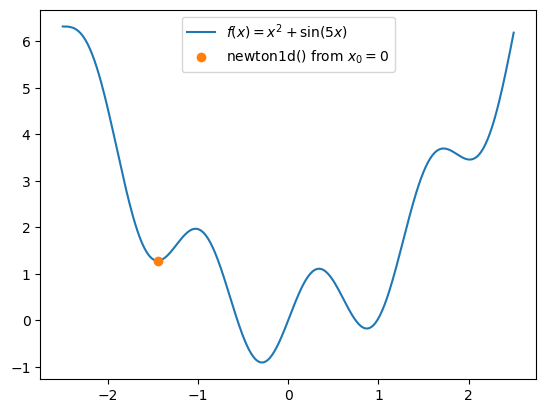

In [7]:
f = lambda x: x**2 + np.sin(5*x)
df = lambda x : 2*x + 5*np.cos(5*x)
d2f = lambda x : 2 - 25*np.sin(5*x)
mine = newton1d(df, d2f, 0, tol=1e-10, maxiters=500)
ref = opt.newton(df, x0=0, fprime=d2f, tol=1e-10, maxiter=500)
print("newton1d():   ", mine)
print("opt.newton(): ", ref)
assert mine[1] and np.isclose(mine[0], ref) and np.isclose(mine[0], -1.4473142236328096)
assert d2f(mine[0]) > 0                     # A local minimizer, not a maximizer.

# Other initial guesses converge to other critical points.
for x0 in [-1, -0.3, 0.5, 0.8]:
    x, conv, _ = newton1d(df, d2f, x0, tol=1e-10, maxiters=500)
    assert conv and np.isclose(x, opt.newton(df, x0=x0, fprime=d2f, tol=1e-10, maxiter=500))
    print(f"x0 = {x0:4}:  x = {x: .10f}, f''(x) = {d2f(x): .2f}")

dom = np.linspace(-2.5, 2.5, 400)
plt.plot(dom, f(dom), label="$f(x) = x^2 + \\sin(5x)$")
plt.plot(mine[0], f(mine[0]), "o", label="newton1d() from $x_0 = 0$")
plt.legend()
plt.show()

Other initial guesses converge to other critical points of $f$: from $-0.3$ and $0.8$ to nearby local minima ($f'' > 0$), but from $-1$ and $0.5$ to local maxima ($f'' < 0$), as the warning above about regions where $f'' \le 0$ predicts.

## The Secant Method

The second derivative of an objective function is not always known or may be prohibitively expensive to evaluate. The *secant method* approximates it with a difference quotient, $f''(x) \approx \frac{f'(x + h) - f'(x)}{h}$. Selecting $x = x_k$ and $h = x_{k-1} - x_k$ gives

$$f''(x_k) \approx \frac{f'(x_k + x_{k-1} - x_k) - f'(x_k)}{x_{k-1} - x_k} = \frac{f'(x_k) - f'(x_{k-1})}{x_k - x_{k-1}}. \tag{11.2}$$

(The spec writes $f(x_k)$ in the last numerator; it is $f'(x_k)$.) Inserting (11.2) into (11.1) gives the complete secant method formula

$$x_{k+1} = x_k - \frac{x_k - x_{k-1}}{f'(x_k) - f'(x_{k-1})}f'(x_k) = \frac{x_{k-1}f'(x_k) - x_kf'(x_{k-1})}{f'(x_k) - f'(x_{k-1})}. \tag{11.3}$$

This recurrence requires two previous points to calculate the next estimate. The method converges superlinearly (slower than Newton's method, but faster than the golden section search), with convergence criteria similar to Newton's method.

## Problem 3: The secant method

> **Problem 3.** Write a function that accepts a first derivative $f'$, starting points $x_0$ and $x_1$, a stopping tolerance `tol`, and a maximum of iterations `maxiter`. Use (11.3) to implement the Secant method. Try to make as few computations as possible by only computing $f'(x_k)$ once for each $k$. Return the minimizer approximation, whether or not the algorithm converged, and the number of iterations computed.
>
> Test your code with the function $f(x) = x^2 + \sin(x) + \sin(10x)$ and with initial guesses of $x_0 = 0$ and $x_1 = -1$. Plot your answer with the graph of the function. Also compare your results to `scipy.optimize.newton()`; without providing the `fprime` argument, this function uses the secant method. However, it still only takes in one initial condition, so it may converge to a different local minimum than your function.
>
> ```python
> >>> df = lambda x: 2*x + np.cos(x) + 10*np.cos(10*x)
> >>> opt.newton(df, x0=0, tol=1e-10, maxiter=500)
> -3.2149595174761636
> ```

In [8]:
def secant1d(df, x0, x1, tol=1e-5, maxiters=15):
    """Use the secant method to minimize a function f:R->R.

    Parameters:
        df (function): The first derivative of f.
        x0 (float): An initial guess for the minimizer of f.
        x1 (float): Another guess for the minimizer of f.
        tol (float): The stopping tolerance.
        maxiters (int): The maximum number of iterations to compute.

    Returns:
        (float): The approximate minimizer of f.
        (bool): Whether or not the algorithm converged.
        (int): The number of iterations computed.
    """
    converged = False
    iterations = 0
    # Save df(x0) and df(x1) so that we don't need to call them every time
    dfx0 = df(x0)
    dfx1 = df(x1)
    for i in range(maxiters):
        iterations += 1
        # Secant method, equation 11.3
        x2 = (x0*dfx1 - x1*dfx0)/(dfx1 - dfx0)
        if abs(x2 - x1) < tol:
            converged = True
            break
        # Update the x values and their derivatives
        dfx0 = dfx1
        dfx1 = df(x2)
        x0 = x1
        x1 = x2

    return x2, converged, iterations

The spec's SciPy call, as run with SciPy 1.16:

In [9]:
df = lambda x: 2*x + np.cos(x) + 10*np.cos(10*x)
opt.newton(df, x0=0, tol=1e-10, maxiter=500)

np.float64(2.3155516573790806)

> **Note.** The spec printed `-3.2149595174761636` for this call. With SciPy 1.16 it returns about $2.3156$, a critical point of $f$ that is a local *maximum* ($f'' < 0$ there). Newer versions of `scipy.optimize.newton()` also accept a second starting point `x1`, but even with $x_0 = 0$, $x_1 = -1$ it finds a different local minimum (about $-0.777$) than `secant1d()`: SciPy first swaps the two starting points so that the one with the smaller $|f'|$ is the most recent, so after the first step it keeps a different pair of points than (11.3) does.

The checks below compare `secant1d()` with SciPy's bounded scalar minimizer and with a bracketing root-finder on $f'$ near its result, and count the derivative evaluations.

secant1d(x0=0, x1=-1):    (np.float64(-0.16367722118190792), True, 10)
opt.newton(x0=0, x1=-1):  -0.7769789899729264
minimize_scalar on [-0.3, 0]: -0.16367722157909598
brentq(f') on [-0.3, 0]:      -0.16367722118190794
10 iterations, 11 evaluations of f'


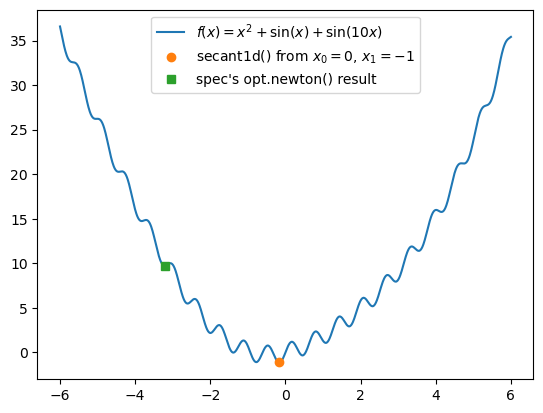

In [10]:
f = lambda x: x**2 + np.sin(x) + np.sin(10*x)
d2f = lambda x: 2 - np.sin(x) - 100*np.sin(10*x)
mine = secant1d(df, 0, -1, tol=1e-10, maxiters=500)
print("secant1d(x0=0, x1=-1):   ", mine)
print("opt.newton(x0=0, x1=-1): ", opt.newton(df, x0=0, x1=-1, tol=1e-10, maxiter=500))
ref1 = opt.minimize_scalar(f, bounds=(-0.3, 0), method="bounded", options={"xatol": 1e-10}).x
ref2 = opt.brentq(df, -0.3, 0, xtol=1e-14)
print("minimize_scalar on [-0.3, 0]:", ref1)
print("brentq(f') on [-0.3, 0]:     ", ref2)
assert mine[1] and np.isclose(mine[0], ref1, atol=1e-8) and np.isclose(mine[0], ref2)
assert abs(df(mine[0])) < 1e-8 and d2f(mine[0]) > 0     # A local minimizer.

# Count derivative evaluations: one per iteration plus the two starting points.
calls = []
def counted_df(x):
    calls.append(x)
    return df(x)
_, _, niters = secant1d(counted_df, 0, -1, tol=1e-10, maxiters=500)
print(f"{niters} iterations, {len(calls)} evaluations of f'")

dom = np.linspace(-6, 6, 1000)
plt.plot(dom, f(dom), label="$f(x) = x^2 + \\sin(x) + \\sin(10x)$")
plt.plot(mine[0], f(mine[0]), "o", label="secant1d() from $x_0 = 0$, $x_1 = -1$")
plt.plot(-3.2149595174761636, f(-3.2149595174761636), "s", label="spec's opt.newton() result")
plt.legend()
plt.show()

## Descent Methods

For $f : \mathbb{R}^n \to \mathbb{R}$, *descent methods* (also called *line search methods*) create a convergent sequence by the rule

$$\mathbf{x}_{k+1} = \mathbf{x}_k + \alpha_k\mathbf{p}_k, \tag{11.4}$$

where $\alpha_k \in \mathbb{R}$ is the *step size* and $\mathbf{p}_k \in \mathbb{R}^n$ is the *search direction*. The choice of $\mathbf{p}_k$ usually distinguishes an algorithm; in one dimension, $p_k = f'(x_k)/f''(x_k)$ gives Newton's method, and the approximation (11.2) gives the secant method.

A descent method also needs a good step size. If $\alpha_k$ is too large, the method may repeatedly overstep the minimum (the spec's Figure 11.3); if it is too small, the method may converge extremely slowly. The best step size minimizes $\phi_k(\alpha) = f(\mathbf{x}_k + \alpha\mathbf{p}_k)$, and since $\phi_k : \mathbb{R} \to \mathbb{R}$, any of the methods above can be used. However, computing the best $\alpha_k$ at every iteration is not always practical. Instead, some methods use a cheap routine to compute a step size that may not be optimal, but which is good enough. The most common approach is to find an $\alpha_k$ that satisfies the *Wolfe conditions*:

$$f(\mathbf{x}_k + \alpha_k\mathbf{p}_k) \le f(\mathbf{x}_k) + c_1\alpha_kDf(\mathbf{x}_k)^\mathsf{T}\mathbf{p}_k \tag{11.5}$$

$$-Df(\mathbf{x}_k + \alpha_k\mathbf{p}_k)^\mathsf{T}\mathbf{p}_k \le -c_2Df(\mathbf{x}_k)^\mathsf{T}\mathbf{p}_k \tag{11.6}$$

where $0 < c_1 < c_2 < 1$ (for the best results, choose $c_1 \ll c_2$). Condition (11.5), the *Armijo rule*, ensures that the step decreases $f$. It is not enough on its own: by Taylor's theorem,

$$f(\mathbf{x}_k + \alpha_k\mathbf{p}_k) = f(\mathbf{x}_k) + \alpha_kDf(\mathbf{x}_k)^\mathsf{T}\mathbf{p}_k + O(\alpha_k^2),$$

so a very small $\alpha_k$ always satisfies (11.5), since $Df(\mathbf{x}_k)^\mathsf{T}\mathbf{p}_k < 0$ for a descent direction. Condition (11.6), the *curvature condition*, ensures that $\alpha_k$ is large enough for the algorithm to make significant progress.

An $\alpha_k$ can satisfy the Wolfe conditions but still be far from the minimizer of $\phi_k(\alpha)$. The *strong Wolfe conditions* modify (11.6) to ensure that $\alpha_k$ is near the minimizer:

$$|Df(\mathbf{x}_k + \alpha_k\mathbf{p}_k)^\mathsf{T}\mathbf{p}_k| \le c_2|Df(\mathbf{x}_k)^\mathsf{T}\mathbf{p}_k|.$$

The *Armijo–Goldstein conditions* are another alternative to (11.6):

$$f(\mathbf{x}_k) + (1 - c)\alpha_kDf(\mathbf{x}_k)^\mathsf{T}\mathbf{p}_k \le f(\mathbf{x}_k + \alpha_k\mathbf{p}_k) \le f(\mathbf{x}_k) + c\alpha_kDf(\mathbf{x}_k)^\mathsf{T}\mathbf{p}_k,$$

where $0 < c < 1$. These are very similar to the Wolfe conditions (the right inequality is (11.5)), but they do not require the directional derivative $Df(\mathbf{x}_k + \alpha_k\mathbf{p}_k)^\mathsf{T}\mathbf{p}_k$.

### Backtracking

A *backtracking line search* starts with a fairly large initial step size $\alpha$, then repeatedly scales it down by a factor $\rho$ until the desired conditions are satisfied. The following algorithm only requires $\alpha$ to satisfy (11.5). This is usually sufficient, but if it finds $\alpha$'s that are too small, it can be modified to satisfy (11.6) or one of its variants.

```text
Algorithm 11.2  Backtracking using the Armijo Rule
1: procedure backtracking(f, Df, x_k, p_k, α, ρ, c)
2:     Dfp ← Df(x_k)ᵀ p_k            ▷ Compute these values only once.
3:     fx ← f(x_k)
4:     while f(x_k + α p_k) > fx + c α Dfp do
5:         α ← ρ α
6:     return α
```

## Problem 4: Backtracking

> **Problem 4.** Write a function that accepts a function $f : \mathbb{R}^n \to \mathbb{R}$, its derivative $Df : \mathbb{R}^n \to \mathbb{R}^n$, an approximate minimizer $\mathbf{x}_k$, a search direction $\mathbf{p}_k$, an initial step length $\alpha$, and parameters $\rho$ and $c$. Implement the backtracking method of Algorithm 11.2. Return the computed step size.
>
> The functions $f$ and $Df$ should both accept 1-D NumPy arrays of length $n$. For example, if $f(x, y, z) = x^2 + y^2 + z^2$, then $f$ and $Df$ could be defined as follows.
>
> ```python
> >>> f = lambda x: x[0]**2 + x[1]**2 + x[2]**2
> >>> Df = lambda x: np.array([2*x[0], 2*x[1], 2*x[2]])
> ```
>
> SciPy's `scipy.optimize.linesearch.scalar_search_armijo()` finds an acceptable step size using the Armijo rule. It may not give the exact answer as your implementation since it decreases $\alpha$ differently, but the answers should be similar.
>
> ```python
> >>> from scipy.optimize import linesearch
> >>> from autograd import numpy as anp
> >>> from autograd import grad
>
> # Get a step size for f(x,y,z) = x^2 + y^2 + z^2.
> >>> f = lambda x: x[0]**2 + x[1]**2 + x[2]**2
> >>> x = anp.array([150., .03, 40.])   # Current minimizer guesss.
> >>> p = anp.array([-.5, -100., -4.5]) # Current search direction.
> >>> phi = lambda alpha: f(x + alpha*p) # Define phi(alpha).
> >>> dphi = grad(phi)
> >>> alpha, _ = linesearch.scalar_search_armijo(phi, phi(0.), dphi(0.))
> ```

> **Note.** `scipy.optimize.linesearch` is deprecated in current SciPy (it is due to be removed in SciPy 2.0), and in SciPy 1.16 it no longer exposes `scalar_search_armijo()`. The function itself still lives in the private module `scipy.optimize._linesearch`, which the cells below use.

In [11]:
def backtracking(f, Df, x, p, alpha=1, rho=.9, c=1e-4):
    """Implement the backtracking line search to find a step size that
    satisfies the Armijo condition.

    Parameters:
        f (function): A function f:R^n->R.
        Df (function): The first derivative (gradient) of f.
        x (float): The current approximation to the minimizer.
        p (float): The current search direction.
        alpha (float): A large initial step length.
        rho (float): Parameter in (0, 1).
        c (float): Parameter in (0, 1).

    Returns:
        alpha (float): Optimal step size.
    """
    # Algorithm 11.2
    Dfp = np.dot(Df(x), p)
    fx = f(x)
    while f(x + alpha*p) > fx + c*alpha*Dfp:
        alpha = rho*alpha
    return alpha

In [12]:
from scipy.optimize._linesearch import scalar_search_armijo   # The spec's linesearch.scalar_search_armijo().

# Get a step size for f(x,y,z) = x^2 + y^2 + z^2.
f = lambda x: x[0]**2 + x[1]**2 + x[2]**2
Df = lambda x: np.array([2*x[0], 2*x[1], 2*x[2]])
x = anp.array([150., .03, 40.])     # Current minimizer guess.
p = anp.array([-.5, -100., -4.5])   # Current search direction.
phi = lambda alpha: f(x + alpha*p)  # Define phi(alpha).
dphi = grad(phi)
alpha_sp, _ = scalar_search_armijo(phi, phi(0.), dphi(0.))

alpha = backtracking(f, Df, x, p)
print(f"backtracking():         alpha = {alpha:.6f}")
print(f"scalar_search_armijo(): alpha = {alpha_sp:.6f}")
print(f"exact minimizer of phi: alpha = {opt.minimize_scalar(phi).x:.6f}")

# alpha satisfies the Armijo rule (11.5), and alpha/rho (the previous trial step) does not.
c, rho = 1e-4, .9
armijo = lambda a: f(x + a*p) <= f(x) + c*a*(Df(x) @ p)
assert armijo(alpha) and not armijo(alpha / rho)
assert armijo(alpha_sp)
print("Armijo condition satisfied; f(x) =", f(x), "->", f(x + alpha*p))

backtracking():         alpha = 0.047101
scalar_search_armijo(): alpha = 0.025747
exact minimizer of phi: alpha = 0.025747
Armijo condition satisfied; f(x) = 24100.0009 -> 24097.92742815714


The two step sizes differ (SciPy's routine interpolates with a quadratic, then cubics, instead of scaling by a fixed $\rho$; since $\phi$ is itself quadratic here, its first interpolation lands exactly on the minimizer of $\phi$) but are of the same order, and both satisfy the Armijo rule.

## Testing all problems: `main()`

`main()` runs the spec's tests for all four problems; Problem 3 also plots $f$. The `.py` version ended with an `if __name__ == ...` guard to run it as a script, which a notebook doesn't need, so `main()` is called directly below.

In [13]:
def main():
    # Test functions for all of the problems.
    plt.ion()
    g = lambda x: np.exp(x) - 4*x
    a = 0
    b = 3
    domain = np.linspace(a, b, 200)
    # Plot prob1
    #plt.plot(domain, g(domain))
    print("Problem 1: ")
    print(golden_section(g, a, b, maxiters=100))
    print(opt.golden(g, brack=(0,3), tol=1e-5))

    dfn = lambda x: 2*x + 5*np.cos(5*x)
    d2fn = lambda x: 2 - 25*np.sin(5*x)
    print("\nProblem 2: ")
    print(newton1d(dfn, d2fn, 0, tol=1e-10, maxiters=500))
    print(opt.newton(dfn, x0=0, fprime=d2fn, tol=1e-10, maxiter=500))

    fs = lambda x: x**2 + np.sin(x) + np.sin(10*x)
    dfs = lambda x: 2*x + np.cos(x) + 10*np.cos(10*x)
    dom_s = np.linspace(-6, 0, 200)
    # Plot prob3
    plt.plot(dom_s, fs(dom_s))
    plt.grid()
    print("\nProblem 3: ")
    s = secant1d(dfs, 0, -1, tol=1e-10, maxiters=500)[0]
    n = opt.newton(dfs, x0=0, tol=1e-10, maxiter=500)
    print(s)
    print(n)
    print(fs(s), fs(n))

    fb = lambda x: x[0]**2 + x[1]**2 + x[2]**2
    Dfb = lambda x: np.array([2*x[0], 2*x[1], 2*x[2]])
    x = anp.array([150., .03, 40.])
    p = anp.array([-.5, -100., -4.5])
    phi = lambda alpha: fb(x + alpha*p)
    dphi = grad(phi)
    print("\nProblem 4: ")
    # Changed: opt.linesearch -> opt._linesearch (scipy.optimize.linesearch no
    # longer exposes scalar_search_armijo in SciPy 1.16; the public module is deprecated).
    alpha, _ = opt._linesearch.scalar_search_armijo(phi, phi(0.), dphi(0.))
    print(alpha)
    print(backtracking(fb, Dfb, x, p))

Problem 1: 
(np.float64(1.386290222451367), True, 24)
1.3862936330678663

Problem 2: 
(np.float64(-1.4473142236328096), True, 49)
-1.4473142236328096

Problem 3: 
-0.16367722118190792
2.3155516573790806
-1.1339815222734482 5.178494565598269

Problem 4: 
0.025747218202684496
0.04710128697246249


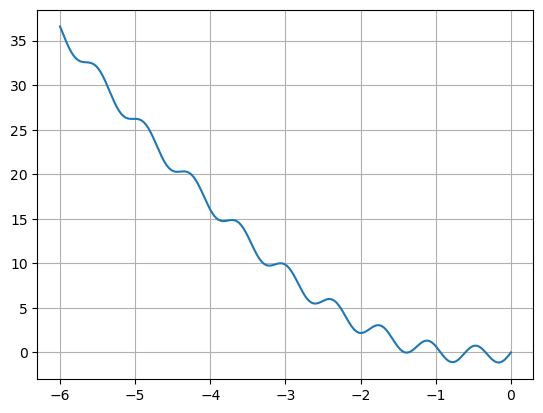

In [14]:
main()